<a href="https://colab.research.google.com/github/vitor-007/am_turma5_prova/blob/main/VitorReina_am_t5_prova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prova Prática 2 — Situação de Trabalho do Estudante Graduando

**Vitor Reina**

**Target do roteiro:** A/B → 0; C/D/E → 1.

| QE_I10 | Situação | Classe |
|---|---|---:|
| A | Não trabalha | 0 |
| B | Trabalha eventualmente | 0 |
| C | Trabalha até 20 h/semana | 1 |
| D | Trabalha de 21 a 39 h/semana | 1 |
| E | Trabalha 40 h/semana ou mais | 1 |

C/D/E não equivale exatamente a “20 horas ou mais”: C inclui jornadas menores.
A questão exclui estágios e bolsas e não mede diretamente a necessidade de trabalhar.


## 1. Bibliotecas e parâmetros

Os parâmetros seguem o enunciado.


In [54]:
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEMENTE = 42
TAMANHO_AMOSTRA = 8000
FRACAO_TESTE = 0.25
ALFA = 0.05
PASTA_DADOS = Path('.')  # Pasta local, quando não estiver no Colab.
sns.set_theme(style='whitegrid')


## 2. Acesso aos dados

No Colab, autorize a mesma conta do Drive que contém a pasta `Dados_Enade2023_Prova2`. A checagem ocorre antes da leitura.


In [55]:
try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    drive.mount('/content/drive')
    raiz_drive = Path('/content/drive/MyDrive')
    if not raiz_drive.is_dir():
        raiz_drive = Path('/content/drive/My Drive')
    PASTA_DADOS = raiz_drive / 'Dados_Enade2023_Prova2'

arquivos = {}
for n in [2, 16, 17]:
    candidatos = [PASTA_DADOS / f'microdados2023_arq{n}{ext}' for ext in ['.csv', '.txt']]
    arquivos[n] = next((p for p in candidatos if p.is_file()), None)
if any(p is None for p in arquivos.values()):
    raise FileNotFoundError(f'Confira a conta do Drive e a pasta dos três arquivos: {PASTA_DADOS.resolve()}')
print('Os três arquivos foram encontrados em:', PASTA_DADOS.resolve())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Os três arquivos foram encontrados em: /content/drive/MyDrive/Dados_Enade2023_Prova2


## 3. Carga e padronização

Os CSVs fornecidos estão em UTF-8, separados por `;`, com aspas externas. A função trata esse formato e preserva a posição das linhas.


In [56]:
def carregar(n, coluna):
    df = pd.read_csv(arquivos[n], sep=';', encoding='utf-8-sig', dtype='string',
                     quoting=csv.QUOTE_NONE, keep_default_na=False, skip_blank_lines=False)
    df.columns = df.columns.str.strip().str.strip('"')
    for c in df.columns:
        df[c] = df[c].str.strip().str.strip('"').str.strip().str.upper().replace('', pd.NA)
    if not {'NU_ANO', 'CO_CURSO', coluna}.issubset(df.columns):
        raise ValueError(f'Colunas esperadas ausentes no arquivo {n}.')
    return df

df_turno_raw = carregar(2, 'CO_TURNO_GRADUACAO')
df_trab_raw = carregar(16, 'QE_I10')
df_bolsa_raw = carregar(17, 'QE_I11')
display(pd.DataFrame({'Arquivo': ['Turno', 'Trabalho', 'Bolsa'],
                      'Linhas': [len(df_turno_raw), len(df_trab_raw), len(df_bolsa_raw)]}))


,Arquivo,Linhas
0,Turno,406294
1,Trabalho,406294
2,Bolsa,406294


## 4. Correspondência entre arquivos

Mesmo número de linhas não garante o mesmo aluno. A coincidência do curso é apenas um diagnóstico; nem ela permite vincular indivíduos.


In [57]:
assert len(df_turno_raw) == len(df_trab_raw) == len(df_bolsa_raw)
pares = [('Turno × Trabalho', df_turno_raw, df_trab_raw),
         ('Turno × Bolsa', df_turno_raw, df_bolsa_raw),
         ('Trabalho × Bolsa', df_trab_raw, df_bolsa_raw)]
display(pd.DataFrame([
    {'Comparação': nome, 'Mesmo curso na mesma linha (%)': a['CO_CURSO'].eq(b['CO_CURSO']).mean() * 100}
    for nome, a, b in pares
]).round(4))
print('Não há vínculo individual: a junção posterior será apenas didática.')


,Comparação,Mesmo curso na mesma linha (%)
0,Turno × Trabalho,0.0554
1,Turno × Bolsa,0.0610
2,Trabalho × Bolsa,0.9373


Não há vínculo individual: a junção posterior será apenas didática.


## 5. Limpeza de dados

Excluímos respostas ausentes, códigos inválidos e metadados inválidos. Não aplicamos `drop_duplicates()`: respostas iguais podem ser de alunos diferentes.


In [58]:
TURNOS = {1: 'Matutino', 2: 'Vespertino', 3: 'Integral', 4: 'Noturno'}
TRABALHO = {'A': 'Não trabalha', 'B': 'Trabalho eventual', 'C': 'Até 20 h/semana',
            'D': '21 a 39 h/semana', 'E': '40 h/semana ou mais'}
BOLSAS = {'A': 'Sem bolsa: curso gratuito', 'B': 'Sem bolsa: curso pago',
          'C': 'ProUni integral', 'D': 'ProUni parcial', 'E': 'FIES',
          'F': 'ProUni parcial + FIES', 'G': 'Bolsa de governo estadual/distrital/municipal',
          'H': 'Bolsa da instituição', 'I': 'Bolsa de outra entidade',
          'J': 'Financiamento da instituição', 'K': 'Financiamento bancário'}
MAPA_TARGET = {'A': 0, 'B': 0, 'C': 1, 'D': 1, 'E': 1}
NOMES_CLASSES = ['Classe 0 — A/B', 'Classe 1 — C/D/E']

def limpar(df, coluna, codigos, nome):
    ausentes = df[coluna].isna()
    invalidos = ~ausentes & ~df[coluna].isin(codigos)
    metadados = df['NU_ANO'].eq('2023') & df['CO_CURSO'].str.fullmatch(r'[1-9]\d*', na=False)
    validos = ~ausentes & ~invalidos & metadados.fillna(False)
    resumo = {'Arquivo': nome, 'Antes': len(df), 'Ausentes': int(ausentes.sum()),
              'Código inválido': int(invalidos.sum()), 'Removidos': int((~validos).sum()),
              'Depois': int(validos.sum())}
    return df.loc[validos].copy(), resumo

turno_limpo, r1 = limpar(df_turno_raw, 'CO_TURNO_GRADUACAO', list('1234'), 'Turno')
trabalho_limpo, r2 = limpar(df_trab_raw, 'QE_I10', TRABALHO, 'Trabalho')
bolsa_limpa, r3 = limpar(df_bolsa_raw, 'QE_I11', BOLSAS, 'Bolsa')
relatorio_limpeza = pd.DataFrame([r1, r2, r3])
display(relatorio_limpeza)


,Arquivo,Antes,Ausentes,Código inválido,Removidos,Depois
0,Turno,406294,0,0,0,406294
1,Trabalho,406294,38571,0,38571,367723
2,Bolsa,406294,38569,0,38569,367725


## 6. AD — tabelas de frequência

Cada percentual usa as respostas válidas do próprio arquivo. Turno, trabalho e bolsa são analisados separadamente.


In [59]:
def frequencias(serie, mapa):
    n = serie.value_counts().reindex(list(mapa), fill_value=0)
    return pd.DataFrame({'Código': list(mapa), 'Descrição': list(mapa.values()),
                         'Quantidade': n.to_numpy(), 'Percentual (%)': n.to_numpy() / len(serie) * 100})

freq_turno = frequencias(turno_limpo['CO_TURNO_GRADUACAO'].astype(int), TURNOS)
freq_trab = frequencias(trabalho_limpo['QE_I10'], TRABALHO)
freq_bolsa = frequencias(bolsa_limpa['QE_I11'], BOLSAS)
for nome, tabela in [('Turno', freq_turno), ('Trabalho', freq_trab), ('Bolsa/financiamento', freq_bolsa)]:
    print(nome)
    display(tabela.round(2))


Turno


,Código,Descrição,Quantidade,Percentual (%)
0,1,Matutino,66206,16.30
1,2,Vespertino,9339,2.30
2,3,Integral,131591,32.39
3,4,Noturno,199158,49.02


Trabalho


,Código,Descrição,Quantidade,Percentual (%)
0,A,Não trabalha,163706,44.52
1,B,Trabalho eventual,30849,8.39
2,C,Até 20 h/semana,17859,4.86
3,D,21 a 39 h/semana,37216,10.12
4,E,40 h/semana ou mais,118093,32.11


Bolsa/financiamento


,Código,Descrição,Quantidade,Percentual (%)
0,A,Sem bolsa: curso gratuito,87446,23.78
1,B,Sem bolsa: curso pago,105668,28.74
2,C,ProUni integral,26620,7.24
3,D,ProUni parcial,7172,1.95
4,E,FIES,24895,6.77
5,F,ProUni parcial + FIES,4400,1.20
6,G,Bolsa de governo estadual/distrital/municipal,9867,2.68
7,H,Bolsa da instituição,72538,19.73
8,I,Bolsa de outra entidade,12478,3.39
9,J,Financiamento da instituição,12817,3.49


## 7. AD — gráficos

Os gráficos mostram as mesmas distribuições das tabelas.


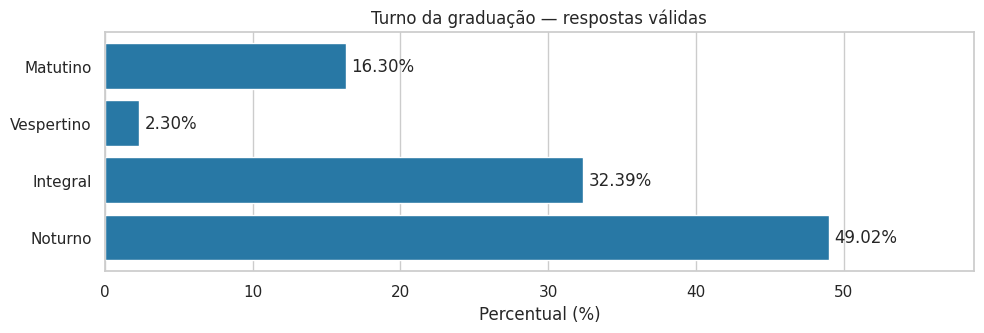

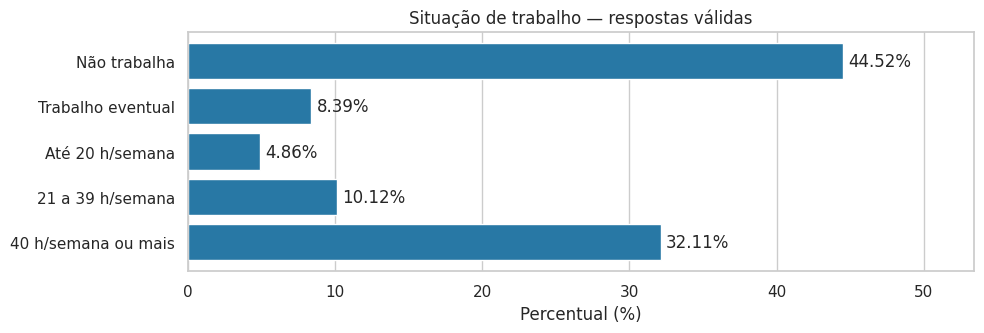

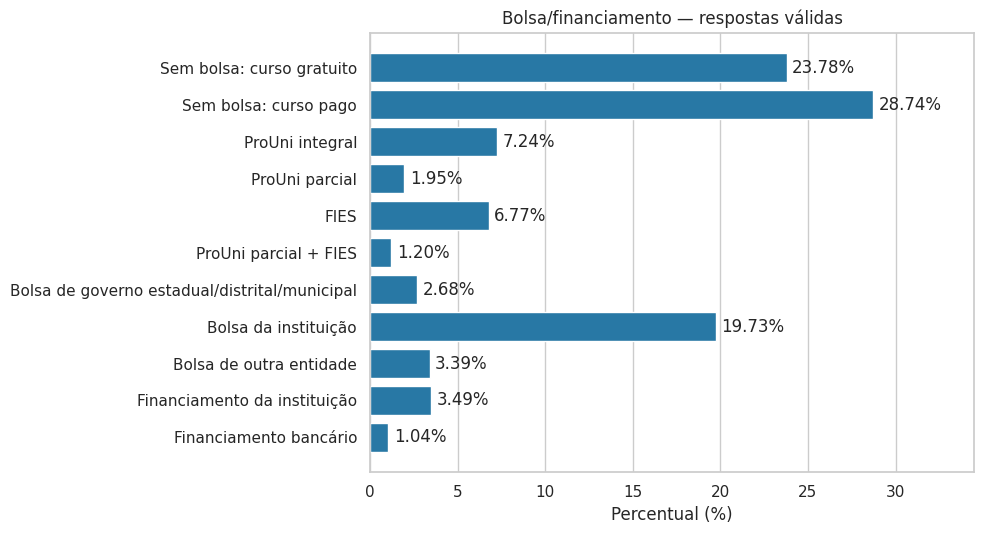

In [60]:
for nome, tabela in [('Turno da graduação', freq_turno), ('Situação de trabalho', freq_trab),
                     ('Bolsa/financiamento', freq_bolsa)]:
    fig, ax = plt.subplots(figsize=(10, max(3.5, len(tabela) * 0.5)))
    barras = ax.barh(tabela['Descrição'], tabela['Percentual (%)'], color='#2878a5')
    ax.bar_label(barras, labels=[f'{p:.2f}%' for p in tabela['Percentual (%)']], padding=4)
    ax.invert_yaxis()
    ax.set(title=f'{nome} — respostas válidas', xlabel='Percentual (%)',
           xlim=(0, tabela['Percentual (%)'].max() * 1.2))
    ax.grid(axis='y', visible=False)
    fig.tight_layout()
    plt.show()


## 8. Target e amostra de 8.000 registros

Primeiro mostramos a proporção marginal válida de trabalho. Depois, a concatenação por posição reproduz o roteiro somente como demonstração; os índices são preservados na limpeza.


In [61]:
target_marginal = trabalho_limpo['QE_I10'].map(MAPA_TARGET).astype(int)
p_marginal = target_marginal.mean()
print(f'P(Y=1) entre respostas válidas do arquivo de trabalho: {p_marginal:.2%}')

df_demo = pd.concat([df_turno_raw[['CO_TURNO_GRADUACAO']],
                     df_trab_raw[['QE_I10']], df_bolsa_raw[['QE_I11']]], axis=1)
validos = (df_demo.index.isin(turno_limpo.index) & df_demo.index.isin(trabalho_limpo.index)
           & df_demo.index.isin(bolsa_limpa.index))
df_demo_limpo = df_demo.loc[validos].copy()
df_demo_limpo['CO_TURNO_GRADUACAO'] = df_demo_limpo['CO_TURNO_GRADUACAO'].astype(int)
df_demo_limpo['target_trabalha'] = df_demo_limpo['QE_I10'].map(MAPA_TARGET).astype(int)
if len(df_demo_limpo) < TAMANHO_AMOSTRA:
    raise ValueError('Há menos de 8.000 registros válidos para a demonstração.')
df_p2 = df_demo_limpo.sample(n=TAMANHO_AMOSTRA, random_state=SEMENTE).copy()
print(f'Demonstração: {len(df_demo)} linhas → {len(df_demo_limpo)} válidas → {len(df_p2)} na amostra.')
display(df_p2['target_trabalha'].value_counts().sort_index().rename('Quantidade').to_frame())


P(Y=1) entre respostas válidas do arquivo de trabalho: 47.09%
Demonstração: 406294 linhas → 367723 válidas → 8000 na amostra.


,Quantidade
target_trabalha,
0,4240
1,3760


## 9. Preditoras e encoding

`QE_I11` é nominal; o LabelEncoder é mantido por exigência do roteiro. Seu vocabulário vem do dicionário, sem aprender com o teste. As dummies usam os quatro turnos oficiais.


In [62]:
le = LabelEncoder().fit(list(BOLSAS))
df_p2['QE_I11_encoded'] = le.transform(df_p2['QE_I11'])
X_p2 = df_p2[['CO_TURNO_GRADUACAO', 'QE_I11_encoded']].copy()
X_p2['CO_TURNO_GRADUACAO'] = pd.Categorical(X_p2['CO_TURNO_GRADUACAO'], categories=list(TURNOS))
X_p2 = pd.get_dummies(X_p2, columns=['CO_TURNO_GRADUACAO'], dtype=int)
y_p2 = df_p2['target_trabalha']
print('Preditoras:', X_p2.columns.tolist())
display(X_p2.head())


Preditoras: ['QE_I11_encoded', 'CO_TURNO_GRADUACAO_1', 'CO_TURNO_GRADUACAO_2', 'CO_TURNO_GRADUACAO_3', 'CO_TURNO_GRADUACAO_4']


,QE_I11_encoded,CO_TURNO_GRADUACAO_1,CO_TURNO_GRADUACAO_2,CO_TURNO_GRADUACAO_3,CO_TURNO_GRADUACAO_4
389339,8,0,0,0,1
284649,4,0,0,0,1
133245,1,0,0,0,1
239598,2,0,0,0,1
240404,2,0,0,0,1


## 10. Treino, teste e padronização

75% para treino e 25% para teste, com estratificação. O StandardScaler é ajustado somente no treino.


In [63]:
X_train_encoded, X_test_encoded, y_train, y_test = train_test_split(
    X_p2, y_p2, test_size=FRACAO_TESTE, random_state=SEMENTE, stratify=y_p2
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)
print(f'Treino: {len(y_train)} | Teste: {len(y_test)}')


Treino: 6000 | Teste: 2000


## 11. GaussianNB e avaliação — demonstração

Acurácia, precisão, recall e F1 descrevem a união artificial do roteiro, não a previsão de alunos reais. Os códigos de bolsa e as dummies também não seguem literalmente uma distribuição gaussiana.


In [64]:
gnb_p2 = GaussianNB().fit(X_train_scaled, y_train)
y_pred_p2 = gnb_p2.predict(X_test_scaled)
acuracia = accuracy_score(y_test, y_pred_p2)
print(f'Acurácia da demonstração: {acuracia:.2%}')
print(classification_report(y_test, y_pred_p2, labels=[0, 1],
                            target_names=NOMES_CLASSES, digits=4, zero_division=0))
print('Probabilidades prévias do treino:', dict(zip(gnb_p2.classes_, gnb_p2.class_prior_)))


Acurácia da demonstração: 98.30%
                  precision    recall  f1-score   support

  Classe 0 — A/B     1.0000    0.9679    0.9837      1060
Classe 1 — C/D/E     0.9651    1.0000    0.9822       940

        accuracy                         0.9830      2000
       macro avg     0.9825    0.9840    0.9830      2000
    weighted avg     0.9836    0.9830    0.9830      2000

Probabilidades prévias do treino: {np.int64(0): np.float64(0.53), np.int64(1): np.float64(0.47)}


## 12. Matriz de confusão

Linhas = classes reais; colunas = classes previstas; diagonal = acertos.


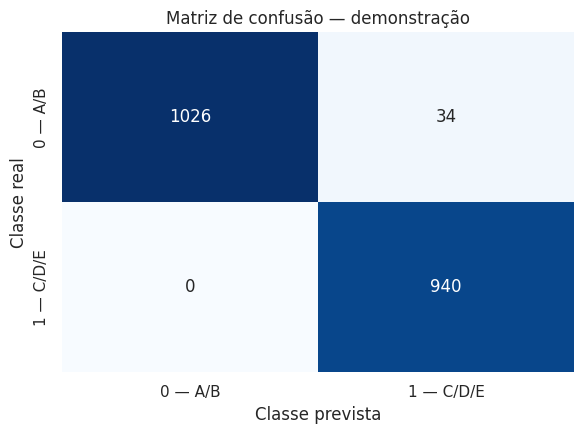

In [65]:
cm = confusion_matrix(y_test, y_pred_p2, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['0 — A/B', '1 — C/D/E'], yticklabels=['0 — A/B', '1 — C/D/E'], ax=ax)
ax.set(title='Matriz de confusão — demonstração', xlabel='Classe prevista', ylabel='Classe real')
ax.grid(False)
fig.tight_layout()
plt.show()


## 13. Matutino versus noturno — demonstração

`P(Y=1 | turno)` é a proporção observada por turno, diferente do prior do modelo. Matutino = 1 e noturno = 4. A diferença é medida em pontos percentuais.


In [66]:
tabela_turnos = df_p2.groupby('CO_TURNO_GRADUACAO')['target_trabalha'].agg(total='size', classe_1='sum')
tabela_turnos = tabela_turnos.reindex(list(TURNOS), fill_value=0)
tabela_turnos['classe_0'] = tabela_turnos['total'] - tabela_turnos['classe_1']
tabela_turnos['Probabilidade (%)'] = tabela_turnos['classe_1'] / tabela_turnos['total'].replace(0, np.nan) * 100
tabela_turnos.insert(0, 'Turno', list(TURNOS.values()))
display(tabela_turnos.round(2))
if (tabela_turnos.loc[[1, 4], 'total'] == 0).any():
    raise ValueError('Faltam registros de matutino ou noturno para a comparação didática.')
p_matutino = tabela_turnos.loc[1, 'Probabilidade (%)'] / 100
p_noturno = tabela_turnos.loc[4, 'Probabilidade (%)'] / 100
diferenca_pp = (p_noturno - p_matutino) * 100
print(f'P(Y=1) marginal na amostra artificial: {y_p2.mean():.2%}')
print(f'Noturno − matutino, na demonstração: {diferenca_pp:+.2f} pontos percentuais.')


,Turno,total,classe_1,classe_0,Probabilidade (%)
CO_TURNO_GRADUACAO,,,,,
1,Matutino,1333,778,555,58.36
2,Vespertino,188,98,90,52.13
3,Integral,2730,1117,1613,40.92
4,Noturno,3749,1767,1982,47.13


P(Y=1) marginal na amostra artificial: 47.00%
Noturno − matutino, na demonstração: -11.23 pontos percentuais.


## 14. Gráfico comparativo dos turnos

Somente ilustração do pareamento artificial; não demonstra associação real entre turno e trabalho.


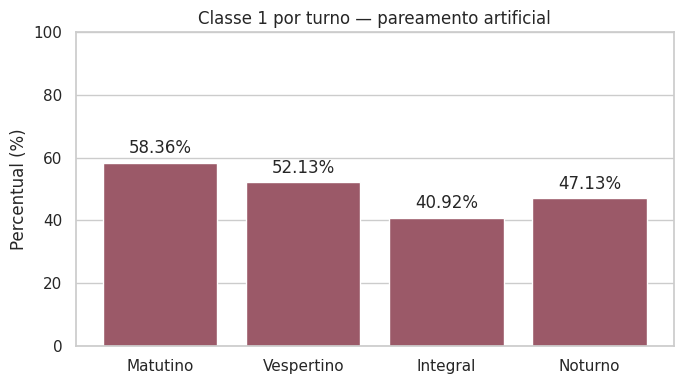

In [67]:
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(tabela_turnos['Turno'], tabela_turnos['Probabilidade (%)'], color='#9b5968')
ax.bar_label(barras, labels=[f'{p:.2f}%' for p in tabela_turnos['Probabilidade (%)']], padding=4)
ax.set(title='Classe 1 por turno — pareamento artificial', ylabel='Percentual (%)', ylim=(0, 100))
ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()


## 15. Significância — procedimento didático

O teste unilateral de Fisher verifica a hipótese de proporção maior no noturno, com α = 5%. Aqui, o p-valor não permite inferência real: falta o vínculo individual. Significância não comprovaria causalidade.


In [68]:
tabela_fisher = tabela_turnos.loc[[4, 1], ['classe_1', 'classe_0']].to_numpy(dtype=int)
odds_ratio_demo, p_valor_demo = fisher_exact(tabela_fisher, alternative='greater')
print(f'p-valor unilateral da demonstração: {p_valor_demo:.6g} | α = {ALFA}')
print('Não usar esse p-valor para concluir sobre estudantes reais.')


p-valor unilateral da demonstração: 1 | α = 0.05
Não usar esse p-valor para concluir sobre estudantes reais.
